# RBM sobre los dígitos de sklearn

Entrenamos una máquina de Boltzmann restringida (`RBM.py`) con las imágenes de 8×8 píxeles de `load_digits` (no es MNIST, que tiene imágenes de 28×28). La RBM aprende a **reconstruir** cada dígito pasando por una capa oculta de solo 50 unidades, así que esas 50 unidades son una representación comprimida de los 64 píxeles.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

from RBM import RBM

## Datos

Los píxeles de `load_digits` van de 0 a 16, así que se dividen entre **16** para dejarlos en [0, 1], que es lo que espera una RBM con unidades visibles Bernoulli.

Entrenamiento: (1347, 64), prueba: (450, 64), rango de pixeles: [0.0, 1.0]


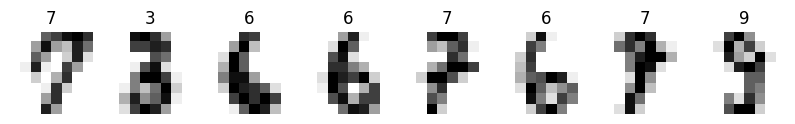

In [2]:
digits = load_digits()
X = digits.data / 16.0
y = digits.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
print(f'Entrenamiento: {X_train.shape}, prueba: {X_test.shape}, rango de pixeles: [{X.min()}, {X.max()}]')

fig, axes = plt.subplots(1, 8, figsize=(10, 2))
for ax, image, label in zip(axes, X_train, y_train):
    ax.imshow(image.reshape(8, 8), cmap='gray_r')
    ax.set_title(label)
    ax.axis('off')

## Entrenamiento

Divergencia contrastiva CD-1 con mini-lotes de 32. Se vigilan dos cosas por época, también con los datos de prueba: el error de reconstrucción y la **energía libre** media (más baja = datos más probables para el modelo). Si la energía libre de prueba se separara de la de entrenamiento habría sobreajuste.

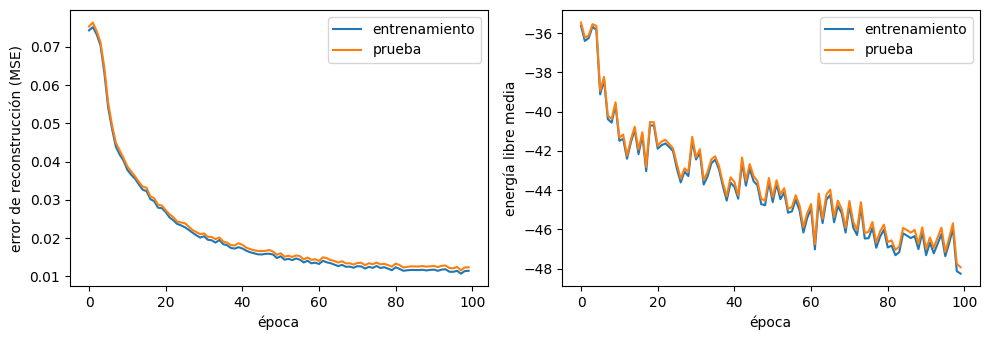

In [3]:
rbm = RBM(n_visible=64, n_hidden=50, seed=0)
history = rbm.train(X_train, lr=0.1, epochs=100, batch_size=32, validation_data=X_test)

fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.5))
a.plot(history['reconstruction_error'], label='entrenamiento')
a.plot(history['val_reconstruction_error'], label='prueba')
a.set_xlabel('época'); a.set_ylabel('error de reconstrucción (MSE)'); a.legend()
b.plot(history['free_energy'], label='entrenamiento')
b.plot(history['val_free_energy'], label='prueba')
b.set_xlabel('época'); b.set_ylabel('energía libre media'); b.legend()
plt.tight_layout()

## Resultado

Se compara con la referencia más simple posible: reconstruir cualquier imagen como la **imagen media** del conjunto de entrenamiento.

Error de reconstruccion en prueba: 0.01240
Referencia (imagen media):         0.07403


Text(0.0, 1.0, 'pesos de 8 unidades ocultas')

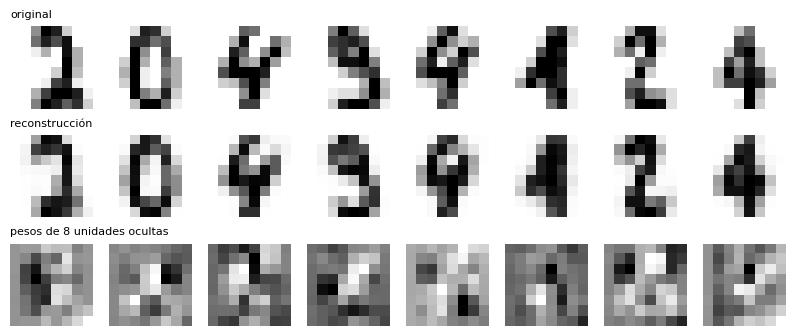

In [4]:
baseline = np.mean((X_test - X_train.mean(axis=0)) ** 2)
print(f'Error de reconstruccion en prueba: {rbm.reconstructionError(X_test):.5f}')
print(f'Referencia (imagen media):         {baseline:.5f}')

reconstructed = rbm.reconstruct(X_test[:8])
fig, axes = plt.subplots(3, 8, figsize=(10, 4))
for i in range(8):
    axes[0, i].imshow(X_test[i].reshape(8, 8), cmap='gray_r')
    axes[1, i].imshow(reconstructed[i].reshape(8, 8), cmap='gray_r')
    axes[2, i].imshow(rbm.W[:, i].reshape(8, 8), cmap='gray')
for ax in axes.ravel():
    ax.axis('off')
axes[0, 0].set_title('original', loc='left', fontsize=8)
axes[1, 0].set_title('reconstrucción', loc='left', fontsize=8)
axes[2, 0].set_title('pesos de 8 unidades ocultas', loc='left', fontsize=8)

## La representación oculta

`encode` devuelve las 50 características de cada imagen. Se usan para entrenar una regresión logística y se compara con usar los 64 píxeles directamente. Los dígitos ya son casi linealmente separables, así que no se espera una mejora: sirve para comprobar que **las 50 características conservan la información** necesaria para clasificar.

In [5]:
from sklearn.linear_model import LogisticRegression

raw = LogisticRegression(max_iter=2000).fit(X_train, y_train).score(X_test, y_test)
feat = LogisticRegression(max_iter=2000).fit(rbm.encode(X_train), y_train).score(rbm.encode(X_test), y_test)
print(f'64 pixeles:           {raw:.4f}')
print(f'50 caracteristicas:   {feat:.4f}')

64 pixeles:           0.9689
50 caracteristicas:   0.9689
